# RQ2 TIB 120: semantic-only rescore v2

**Không chạy Qwen, không sinh lại tóm tắt.** Notebook đọc 240 prediction và ROUGE-L đã lưu, chấm lại toàn bộ BERTScore + source SBERTScore bằng scorer v2. Lỗi retokenized window được sửa bằng cách chia trực tiếp token IDs, không cắt bỏ token. Hai encoder/revision và công thức chính giữ như protocol gốc; implementation mới được ghi thành scoring amendment, không giả định khớp identity v1.

Chuẩn bị Drive: giữ `MyDrive/RQ2_TIB_120_20261012/data` và toàn bộ `formal-run-v1` gồm `frozen-receipt.json` + `dispatches.jsonl`. Dừng phiên cũ; nên dùng phiên T4 mới để tránh giữ model cũ trong GPU. Chọn CPU bằng DEVICE nếu cần. Kết quả mới ở `semantic-rescore-v2`; không sửa/xóa thư mục gốc. Chạy theo thứ tự. 28 semantic scores v1 không được dùng lại; cả 120 mẫu được chấm theo cùng scorer mới.

Thời gian/resource generation cũ và chi phí rescore được báo riêng. Creator abstracts không phải factual-summary GT đã xác minh. Kết quả vẫn chỉ mô tả cohort; grouped intervals là exploratory, không chứng minh superiority trong quần thể.


In [1]:
# Validate supplied identity and all 120 source/reference hashes before pip or model loading.
import gzip, hashlib, json, pathlib, time
from google.colab import drive
drive.mount('/content/drive')
ROOT = pathlib.Path('/content/drive/MyDrive/RQ2_TIB_120_20261012')
DATA = ROOT/'data'; RUN = ROOT/'formal-run-v1'
MANIFEST = json.loads((DATA/'tib-rq2-rq4-120-cohort-261012.json').read_text(encoding='utf8'))
PROTOCOL = json.loads((DATA/'tib-rq2-rq4-120-protocol-261012.json').read_text(encoding='utf8'))
def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False,
        separators=(',', ':'), allow_nan=False).encode()).hexdigest()
assert digest({k:v for k,v in MANIFEST.items() if k!='manifest_sha256'}) == MANIFEST['manifest_sha256']
assert digest({k:v for k,v in PROTOCOL.items() if k!='protocol_sha256'}) == PROTOCOL['protocol_sha256']
assert PROTOCOL['cohort_manifest_sha256']==MANIFEST['manifest_sha256']
assert PROTOCOL['selected_count']==120 and len(MANIFEST['selected'])==120
bundle_file = DATA/'tib-evaluation-120.jsonl.gz'
items=[]; payload=hashlib.sha256(); complete=False; metadata=None
with gzip.open(bundle_file,'rt',encoding='utf8',newline='') as stream:
    for line in stream:
        record=json.loads(line)
        if record.get('kind')=='checksum':
            assert record['sha256']==payload.hexdigest(); complete=True; continue
        assert not complete
        payload.update(line.encode('utf8'))
        if record['kind']=='metadata': metadata=record['value']
        elif record['kind']=='item': items.append(record['value'])
        else: raise ValueError('Unexpected bundle record')
assert complete and len(items)==120
assert payload.hexdigest()==MANIFEST['bundle']['payload_sha256']
by_id={f"{r['split']}/{r['source_index']}":r for r in items}
assert len(by_id)==120 and set(by_id)=={r['id'] for r in MANIFEST['selected']}
for entry in MANIFEST['selected']:
    item=by_id[entry['id']]
    for text_field, hash_field in [('source_text','source_sha256'),('reference_text','reference_sha256')]:
        assert hashlib.sha256(item[text_field].encode('utf8')).hexdigest()==entry[hash_field]==item[hash_field]
assert metadata['selection_sha256']==MANIFEST['selection_sha256']
print('Frozen inputs verified:', len(items), 'records; cohort', MANIFEST['manifest_sha256'])
SESSION_START=time.monotonic()

assert MANIFEST['manifest_sha256']=='ed52d8a41a89ffbdc033b8ec88c04eaf17c4b36393dc8c6d3701415c4b92e918'
assert PROTOCOL['protocol_sha256']=='b77d056a26145c3182c53d1fd65d02dc88ba5131d99495c93a9e033024309910'
ORIGIN_DIR = RUN
OUT = ROOT/'semantic-rescore-v2'  # separate from original formal-run-v1
DEVICE = 'cuda'  # change to 'cpu' if no GPU; different device needs a NEW OUT folder
BATCH_SIZE = 16  # CPU: optionally 4; changed scorer/batch identity needs a NEW OUT
RETRY_FAILED = False  # explicit opt-in only after inspecting saved errors
assert OUT.resolve()!=ORIGIN_DIR.resolve()
if not (ORIGIN_DIR/'frozen-receipt.json').exists():
    raise FileNotFoundError('Original frozen-receipt.json missing; copy the full original run folder to Drive first.')
if not (ORIGIN_DIR/'dispatches.jsonl').exists():
    raise FileNotFoundError('Original dispatches.jsonl missing; keep the original call ledger.')
bundle={'metadata':metadata, 'items':items}
print('Read-only original run:',ORIGIN_DIR)
print('New semantic results:',OUT,'| device:',DEVICE)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frozen inputs verified: 120 records; cohort ed52d8a41a89ffbdc033b8ec88c04eaf17c4b36393dc8c6d3701415c4b92e918
Read-only original run: /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1
New semantic results: /content/drive/MyDrive/RQ2_TIB_120_20261012/semantic-rescore-v2 | device: cuda


In [2]:
# Install only missing/incompatible evaluation packages. Keep native NumPy stack intact.
import importlib.metadata, subprocess, sys
from packaging.requirements import Requirement
requirements=['transformers>=4.45,<5', 'sentence-transformers>=3,<6',
              'bert-score==0.3.13', 'sentencepiece>=0.2,<1', 'huggingface_hub>=0.25,<1']
missing=[]
for text in requirements:
    requirement=Requirement(text)
    try:
        installed=importlib.metadata.version(requirement.name)
        if installed not in requirement.specifier: missing.append(text)
    except importlib.metadata.PackageNotFoundError:
        missing.append(text)
if missing:
    subprocess.run([sys.executable,'-m','pip','install',*requirements],check=True)
    raise RuntimeError('Evaluation dependencies installed. Restart session, then rerun from the first cell to avoid stale binary modules. Files on Drive remain unchanged.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
if DEVICE=='cuda' and not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU available: enable T4 or set DEVICE=cpu before loading scorers.')
print('Evaluation device:',torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'CPU')


Evaluation device: Tesla T4


In [3]:
#@title Load verified bundled scoring code (no editing needed)
import base64, gzip
PAYLOAD = (
'...'
)
SOURCES=json.loads(gzip.decompress(base64.b64decode(PAYLOAD)))
EXPECTED_HASHES = {'rq2_tib_frozen_runtime': '29d44022479ef6b4dc9f2ecf58f61d539ca49686fed6e50ba646153131b86f09', 'rq2_tib_frozen_analysis': 'c2859e18b44607fb1fa1c59f71d22596a0fd0bd6a0567177fe29e4030ad99f3d', 'rq2_tib_benchmark': 'a873bc00bb58e37763b5964246542bbcc428a8f56e385c592fa43a31b777f00d', 'rq2_tib_benchmark_pair': 'ff6168e9073a6b3f9d86223a243667fa1ef7bdf32c7e9009f2c4296607c6fb92', 'rq2_controlled_validation': 'dd4427a53a66c59e13184e0e38f0598ef562bd0faeb0216421764b8344c6bbe7', 'rq2_local_hf_backend': '286c0dd5862e730dc626b3b3bc6fa84b92fc4b979195bf8fe3dd48f6c841a4f2', 'rq2_tib_benchmark_bundle': 'd7718624f37121c9d71c611541d1d16353ce236d5af08996c33311af3cd8e2d4', 'rq2_tib_benchmark_dataset': 'd34cad271aa32f6b5c6a615dee34cb0852ecc1bd56b16ce0dfdea9ff1cd4ed6c', 'rq2_tib_benchmark_metrics': '5ed3e9fbf89d7ac77f41701cb3970db53b638695e50247b702bbe3482f0846b9', 'rq2_tib_benchmark_results': 'f08d2168983e706525f13ea1379a29d0f2ad9dc13bb186068c630f035f04fd2d', 'rq2_tib_pilot_runtime': 'fa129ed76979c55f428fdeb051f81d68b6eaa6032dc69aed0b7226108a7a2c54', 'rq2_tib_semantic_v2': '0861311420de18154e0c31fe566a24c3c27f396ece2dcb4ea2cbe9754bfed808', 'rq2_tib_rescore_runtime': 'ec822fc663c55377d6932c2c7b0dbcba0bf2f582507b7e2a06dd53dccaaf4676', 'rq2_tib_rescore_visualization': 'd85406f768349ac67bf590fcdfa38b61f466b47bac7c536350abdba35bfd670f'}
CODE=pathlib.Path('/content/rq2_semantic_rescore_v2_code')
for name, source in SOURCES.items():
    actual=hashlib.sha256(source.encode()).hexdigest()
    assert actual==EXPECTED_HASHES[name]
    if name in PROTOCOL['code_sha256']: assert actual==PROTOCOL['code_sha256'][name]
for name, module in list(sys.modules.items()):
    if name.startswith('experiments') and getattr(module,'__file__',None):
        if not pathlib.Path(module.__file__).resolve().is_relative_to(CODE.resolve()):
            raise RuntimeError('Other benchmark modules are loaded. Restart session and rerun this notebook to use the verified scoring code.')
for folder in (CODE/'experiments', CODE/'experiments/scripts'):
    folder.mkdir(parents=True,exist_ok=True)
    (folder/'__init__.py').write_text('')
for name,source in SOURCES.items():
    (CODE/'experiments/scripts'/f'{name}.py').write_text(source,encoding='utf-8')
sys.path.insert(0,str(CODE))
from experiments.scripts.rq2_tib_rescore_runtime import validate_origin,run_rescore,summarize_rescore
from experiments.scripts.rq2_tib_semantic_v2 import SemanticScorerV2
from experiments.scripts.rq2_tib_benchmark_metrics import sentences
origin=validate_origin(ORIGIN_DIR,bundle,MANIFEST,PROTOCOL)
OUT.mkdir(parents=True,exist_ok=True)
print('Verified original 120 records, both generated arms, source/reference identities and dispatch ledger.')


Verified original 120 records, both generated arms, source/reference identities and dispatch ledger.


## Load encoders and verify repaired windowing

Chỉ nạp hai semantic encoders. Kiểm câu ngắn so với SentenceTransformer.encode và kiểm dữ liệu thật `valid/208` trước vòng chấm lại. Không dùng điểm hay nhãn để loại mẫu. Nếu kiểm tra thất bại, dừng để xem lỗi, không bật truncation hoặc bỏ mẫu.


In [4]:
last_log=[0.0]
def show_progress(event):
    now=time.monotonic()
    important=event.get('status') in ('failed','completed','interrupted') and event.get('stage') not in ('source_embedding','sentence_windows')
    if important or now-last_log[0]>=5:
        print(event,flush=True);last_log[0]=now
metric_started=time.monotonic()
scorer=SemanticScorerV2(device=DEVICE,batch_size=BATCH_SIZE,on_event=show_progress).load()
samples=['Hello world.','Một câu tiếng Việt.','中文句子。']
direct=scorer._sentence_vectors(samples)
expected=scorer._sentence.encode(samples,batch_size=BATCH_SIZE,
    convert_to_numpy=True,normalize_embeddings=True,show_progress_bar=False)
assert np.allclose(direct,expected,atol=1e-5,rtol=1e-4), 'Short-input embedding equivalence failed'
old_by_id={r['id']:r for r in origin['rows']}
case=by_id['valid/208']
for label,text in [('source',case['source_text']),
                   ('S1',old_by_id['valid/208']['arms']['S1']['summary']),
                   ('S3',old_by_id['valid/208']['arms']['S3']['summary'])]:
    vectors=scorer._sentence_vectors(sentences(text),input_kind='regression_'+label)
    assert np.isfinite(vectors).all()
    print('valid/208 window preflight:',label,'sentences',len(vectors))
metric_initialization_seconds=time.monotonic()-metric_started
import platform
environment={'device':DEVICE,'gpu_name':torch.cuda.get_device_name(0) if DEVICE=='cuda' else None,
    'platform':platform.platform(),'cpu':platform.processor(),'torch':torch.__version__,
    'cpu_threads':torch.get_num_threads(),'scorer':scorer.metadata,
    'initialization_and_preflight_seconds':metric_initialization_seconds}
environment_path=OUT/f'scoring-environment-{time.time_ns()}.json'
environment_path.write_text(json.dumps(environment,indent=2),encoding='utf-8')
print('This scoring session environment:',environment_path)
print('Scorer v2 preflight passed; initialization+preflight seconds:',metric_initialization_seconds)


{'stage': 'model_loading', 'status': 'started', 'model': 'FacebookAI/xlm-roberta-large'}


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

... (18 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'stage': 'model_loading', 'status': 'completed', 'model': 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2', 'elapsed_seconds': 22.562545728000032}


You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
Token indices sequence length is longer than the specified maximum sequence length for this model (134 > 128). Running this sequence through the model will result in indexing errors


valid/208 window preflight: source sentences 51
valid/208 window preflight: S1 sentences 8
valid/208 window preflight: S3 sentences 5
This scoring session environment: /content/drive/MyDrive/RQ2_TIB_120_20261012/semantic-rescore-v2/scoring-environment-1791868225886074387.json
Scorer v2 preflight passed; initialization+preflight seconds: 74.98182854299998


## Rescore all 120 pairs

Checkpoint sau từng mẫu; resume cùng identity sẽ dùng lại điểm v2 đã hoàn tất. Mẫu lỗi được ghi, vòng chạy tiếp tục các mẫu sau. RETRY_FAILED mặc định False; chỉ bật khi chủ động thử lại lỗi đã xem. Không có automatic generation retry. Không chạy đồng thời hai phiên cùng OUT. Nếu tiến trình bị kill và còn `.rescore.lock`, xác nhận phiên cũ đã dừng rồi mới xóa riêng lock đó; không xóa receipt.


In [5]:
receipt=run_rescore(ORIGIN_DIR,bundle,scorer,OUT,device=DEVICE,
    metric_initialization_seconds=metric_initialization_seconds,
    retry_failed=RETRY_FAILED,on_event=show_progress)
summary=summarize_rescore(receipt)
print('Rescore coverage:',summary['counts'])
for metric,report in summary['metrics'].items():
    print(metric,report['overall']['paired_scored'],'/ 120')


{'stage': 'bertscore', 'status': 'completed', 'arm': 'S1', 'score': 0.8558303117752075, 'elapsed_seconds': 0.2630904439999995, 'id': 'valid/0'}
{'stage': 'bertscore', 'status': 'completed', 'arm': 'S3', 'score': 0.8549470901489258, 'elapsed_seconds': 0.12799282499997844, 'id': 'valid/0'}
{'stage': 'sbertscore', 'status': 'completed', 'arm': 'S1', 'score': 0.6687245305095401, 'elapsed_seconds': 0.5469914490000178, 'id': 'valid/0'}
{'stage': 'sbertscore', 'status': 'completed', 'arm': 'S3', 'score': 0.673835854445185, 'elapsed_seconds': 0.5479054710000355, 'id': 'valid/0'}
{'stage': 'rescore', 'id': 'valid/0', 'status': 'completed'}
{'stage': 'bertscore', 'status': 'completed', 'arm': 'S1', 'score': 0.8335149884223938, 'elapsed_seconds': 0.05056720900000755, 'id': 'valid/7'}
{'stage': 'bertscore', 'status': 'completed', 'arm': 'S3', 'score': 0.7899234890937805, 'elapsed_seconds': 0.12162780900001735, 'id': 'valid/7'}
{'stage': 'sbertscore', 'status': 'completed', 'arm': 'S1', 'score': 0.

Token indices sequence length is longer than the specified maximum sequence length for this model (598 > 512). Running this sequence through the model will result in indexing errors
You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


{'stage': 'bertscore', 'status': 'completed', 'arm': 'S1', 'score': 0.8357680474058465, 'elapsed_seconds': 0.15991390400000682, 'id': 'valid/88'}
{'stage': 'bertscore', 'status': 'completed', 'arm': 'S3', 'score': 0.8548394936232594, 'elapsed_seconds': 0.22375877399997535, 'id': 'valid/88'}
{'stage': 'sbertscore', 'status': 'completed', 'arm': 'S1', 'score': 0.6966849473806528, 'elapsed_seconds': 1.2976018570000178, 'id': 'valid/88'}
{'stage': 'sbertscore', 'status': 'completed', 'arm': 'S3', 'score': 0.6869081969444568, 'elapsed_seconds': 1.2991415729999858, 'id': 'valid/88'}
{'stage': 'rescore', 'id': 'valid/88', 'status': 'completed'}
{'stage': 'bertscore', 'status': 'completed', 'arm': 'S1', 'score': 0.8462053537368774, 'elapsed_seconds': 0.09284983100002364, 'id': 'valid/95'}
{'stage': 'bertscore', 'status': 'completed', 'arm': 'S3', 'score': 0.8256190419197083, 'elapsed_seconds': 0.09916583500000797, 'id': 'valid/95'}
{'stage': 'sbertscore', 'status': 'completed', 'arm': 'S1', 's

## Aggregate, full tables and figures

Các bảng gồm đầy đủ 120 ID, failure/pending ledger, per-stratum paired means, grouped intervals và toàn bộ reference/S1/S3 có thể mở từng mẫu. PNG/CSV ghi vào thư mục rescore mới. Điểm thiếu giữ null, không gán 0. Không gộp thời gian rescore vào generation costs lịch sử.


### Coverage and paired means — amended semantic scorer v2

,metric,selected,paired_scored,unscored,S1,S3,S3_minus_S1
0,rouge_l,120,120,0,0.120495,0.123764,0.003269
1,bertscore,120,120,0,0.849552,0.851660,0.002108
2,sbertscore,120,120,0,0.622266,0.625838,0.003572


**rouge_l**

,stratum,selected,paired_scored,unscored,S1,S3,S3_minus_S1
0,short,40,40,0,0.129609,0.130376,0.000767
1,medium,40,40,0,0.115849,0.120221,0.004372
2,long,40,40,0,0.116028,0.120695,0.004667


**bertscore**

,stratum,selected,paired_scored,unscored,S1,S3,S3_minus_S1
0,short,40,40,0,0.854027,0.857113,0.003085
1,medium,40,40,0,0.848293,0.849668,0.001375
2,long,40,40,0,0.846335,0.848200,0.001865


... (3 outputs left out)

### All selected IDs; unavailable scores remain missing

id,stratum,status,error,rouge_l_S3_minus_S1,bertscore_S3_minus_S1,sbertscore_S3_minus_S1
valid/0,short,completed,None,-0.002263,-0.000883,0.005111
valid/7,long,completed,None,-0.051517,-0.043591,0.044025
valid/14,medium,completed,None,0.027178,0.007557,0.027846
valid/34,medium,completed,None,0.041010,0.010444,-0.042801
valid/39,medium,completed,None,-0.041224,-0.037536,-0.077036
valid/42,short,completed,None,0.030060,0.008378,-0.014755
valid/44,short,completed,None,0.048454,-0.003161,-0.094149
valid/48,long,completed,None,-0.002674,-0.001396,0.051446
valid/49,medium,completed,None,-0.008539,0.019600,-0.026985
valid/54,medium,completed,None,0.033989,0.018221,0.029139


**Failures / pending records**

,id,stratum,status,error,rouge_l_S3_minus_S1,bertscore_S3_minus_S1,sbertscore_S3_minus_S1


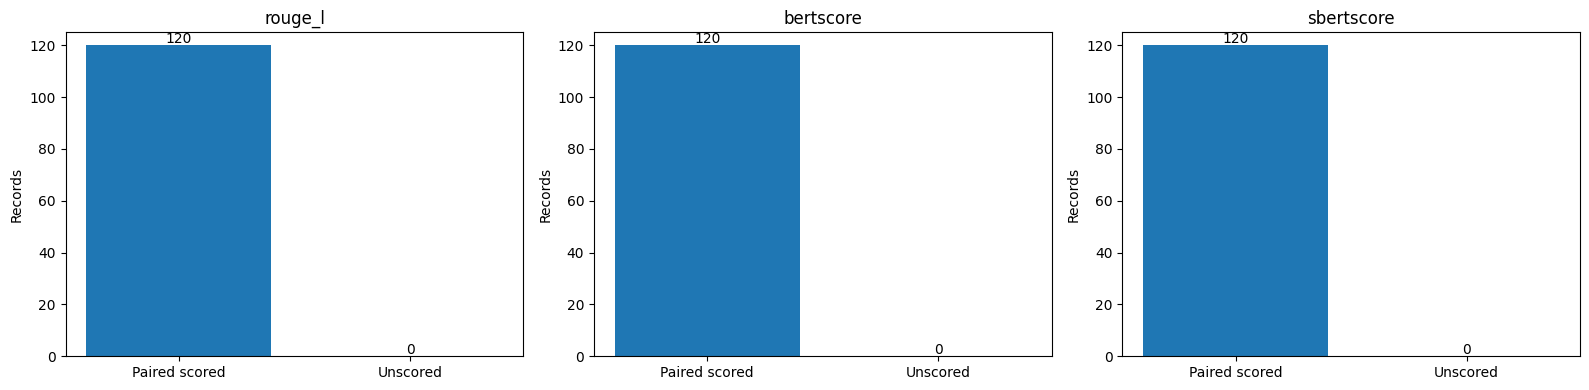

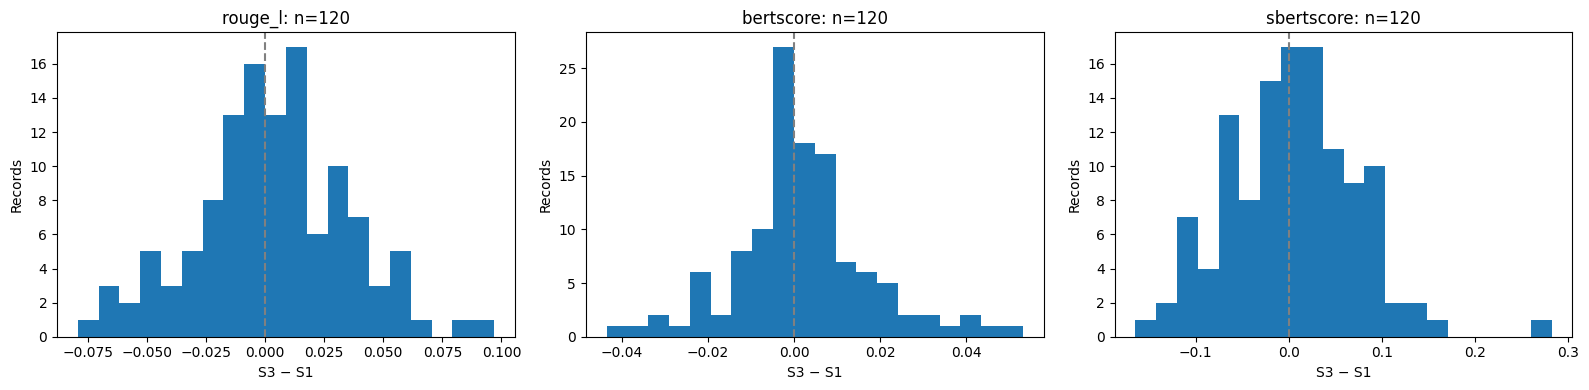

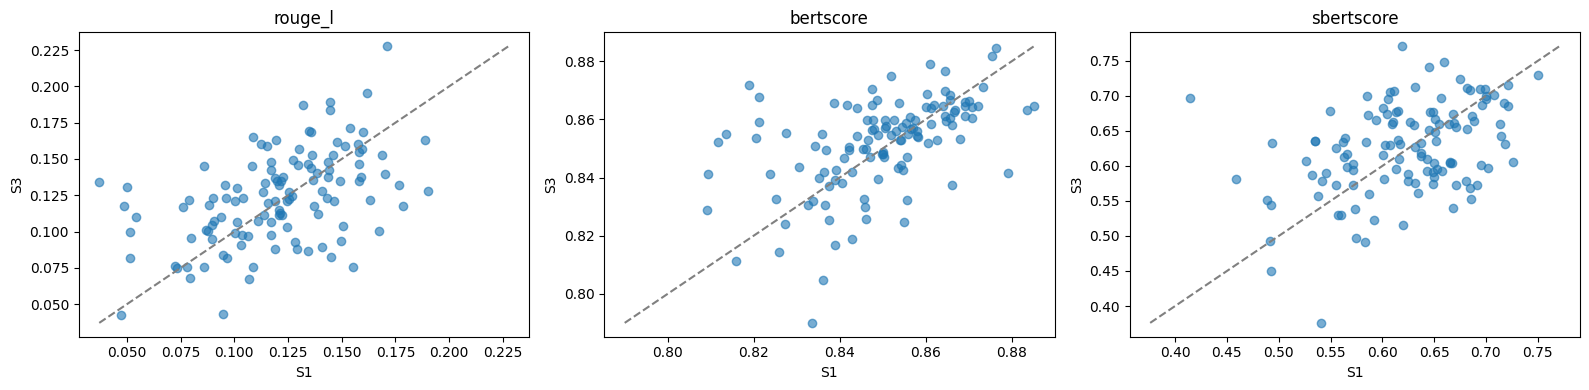

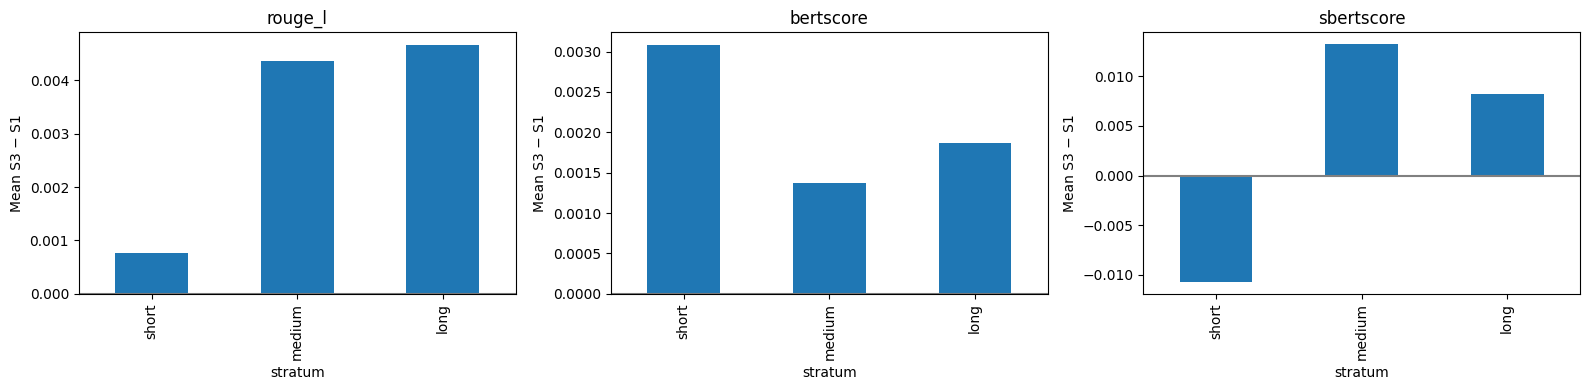

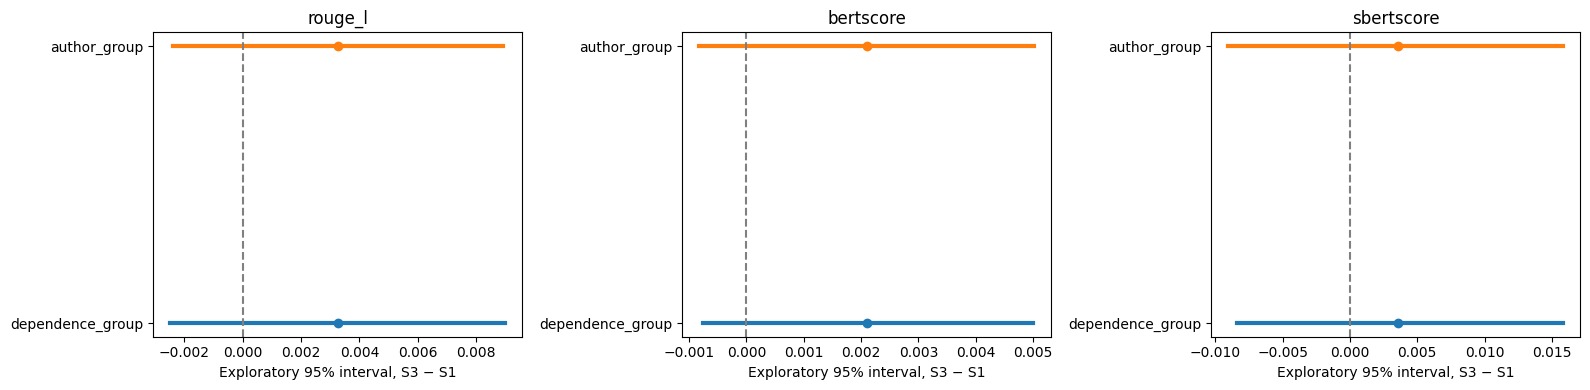

### Original generation costs; rescore costs reported separately

,attempts,prompt_tokens,output_tokens,generation_seconds,segmentation_seconds,usage_incomplete_attempts
S1,120.0,894704.0,179524.0,4892.003137,455.855550,0.0
S3,120.0,899830.0,177929.0,4775.379347,435.636479,0.0


,attempts,known_scoring_seconds,unknown_duration_attempts
0,120,142.760125,0


,initialization_seconds,retry_failed,device,scoring_seconds
0,74.981829,False,cuda,205.054121


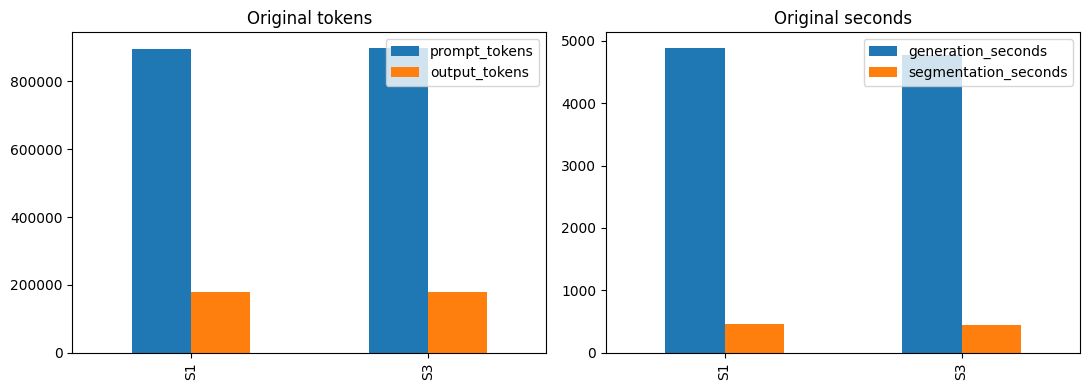

Claim: finite-cohort descriptive; creator abstracts are not verified factual summaries.
BERTScore and source SBERTScore are not factuality percentages.
Complete semantic coverage: True
Tables, original texts, plots and receipts: /content/drive/MyDrive/RQ2_TIB_120_20261012/semantic-rescore-v2
Aggregate: /content/drive/MyDrive/RQ2_TIB_120_20261012/semantic-rescore-v2/aggregate-report.json
Original run preserved: /content/drive/MyDrive/RQ2_TIB_120_20261012/formal-run-v1


In [6]:
from experiments.scripts.rq2_tib_rescore_visualization import render_rescore
(OUT/'aggregate-report.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
render_rescore(receipt,summary,origin,bundle,OUT)
print('Aggregate:',OUT/'aggregate-report.json')
print('Original run preserved:',ORIGIN_DIR)


## Completion and handoff

Hoàn tất semantic khi cả BERTScore và source SBERTScore có **120/120 paired scored**, không có failure/pending/interrupted. Nếu thiếu điểm, notebook vẫn xuất coverage và ledger, không tuyên bố hoàn tất. Giữ `aggregate-report.json`, receipt rescore, bảng CSV, PNG và notebook có outputs để nhận xét. Lần chuẩn bị này chỉ kiểm code/tests; chưa chạy pretrained encoders trên Colab hay chấm lại 120 mẫu.
